# EP11｜AI 寫的程式為什麼越寫越爛？

像素腦底加！這是影片裡的「照抄模擬器」，按上方的 **執行階段 → 全部執行**（或每格按 ▶️）就能自己跑一遍。

規則很簡單：每寫一段新程式，就從專案裡挑一段現有的寫法來模仿。一開始 60 段裡只有 1 段是「補洞寫法」，看它會不會擴散，
再比較「說明檔多寫一行」和「寫成自動檢查（lint）」的差別。

⚠️ 這是簡化的模擬，不是真的 AI。「補洞寫法被挑中的機會是 2 倍」「AI 照做說明檔的比例」「卡住時自己想出補洞的機率」都是假設，用來看趨勢。

📚 參考：Lauren Tan〈All Code Is Slop (Except Mine)〉，AI Engineer CODE 2026：https://ai.engineer/talks/O_zcc6Xl12g-all-code-is-slop-except-mine

📺 影片：[youtube.com/@pixelbraintw](https://www.youtube.com/@pixelbraintw)

## 0. 準備

In [1]:
import random
import re
import matplotlib.pyplot as plt

## 1. 照抄模擬器

`bad_weight`：補洞寫法被挑中的機會是正規寫法的幾倍。`rule`：`none`（沒規則）、`prose`（說明檔，`obey` 的機率照做）、`lint`（自動檢查）。

In [2]:
def simulate(weeks=12, start_good=59, start_bad=1, per_week=30, bad_weight=1.0,
             rule="none", obey=0.9, seed=0):
    """回傳每週結束時「補洞寫法」的數量。
    bad_weight：補洞寫法比較短、測試馬上過，被挑中的機會是正規寫法的幾倍（假設）。
    rule：none（沒有規則）、prose（說明檔寫一行，agent 有 obey 的機率照做）、lint（自動檢查，抄了就擋下來重寫）。
    """
    rng = random.Random(seed)
    good, bad = start_good, start_bad
    hist = [bad]
    for _ in range(weeks):
        for _ in range(per_week):
            p_bad = bad * bad_weight / (bad * bad_weight + good)
            if rng.random() < p_bad:            # 挑到補洞寫法來模仿
                if rule == "lint":
                    good += 1                    # 檢查沒過，agent 只好改用正規寫法
                elif rule == "prose" and rng.random() < obey:
                    good += 1                    # 這次有照說明檔做
                else:
                    bad += 1                     # 照抄了
            else:
                good += 1
        hist.append(bad)
    return hist


def mean_hist(runs=2000, **kw):
    hs = [simulate(seed=s, **kw) for s in range(runs)]
    return [round(sum(h[i] for h in hs) / runs, 1) for i in range(len(hs[0]))]

## 2. 12 週後會有幾段補洞寫法？

一樣容易被挑中： 1.0 -> 7.0
被挑中機會 2 倍： 1.0 -> 37.3


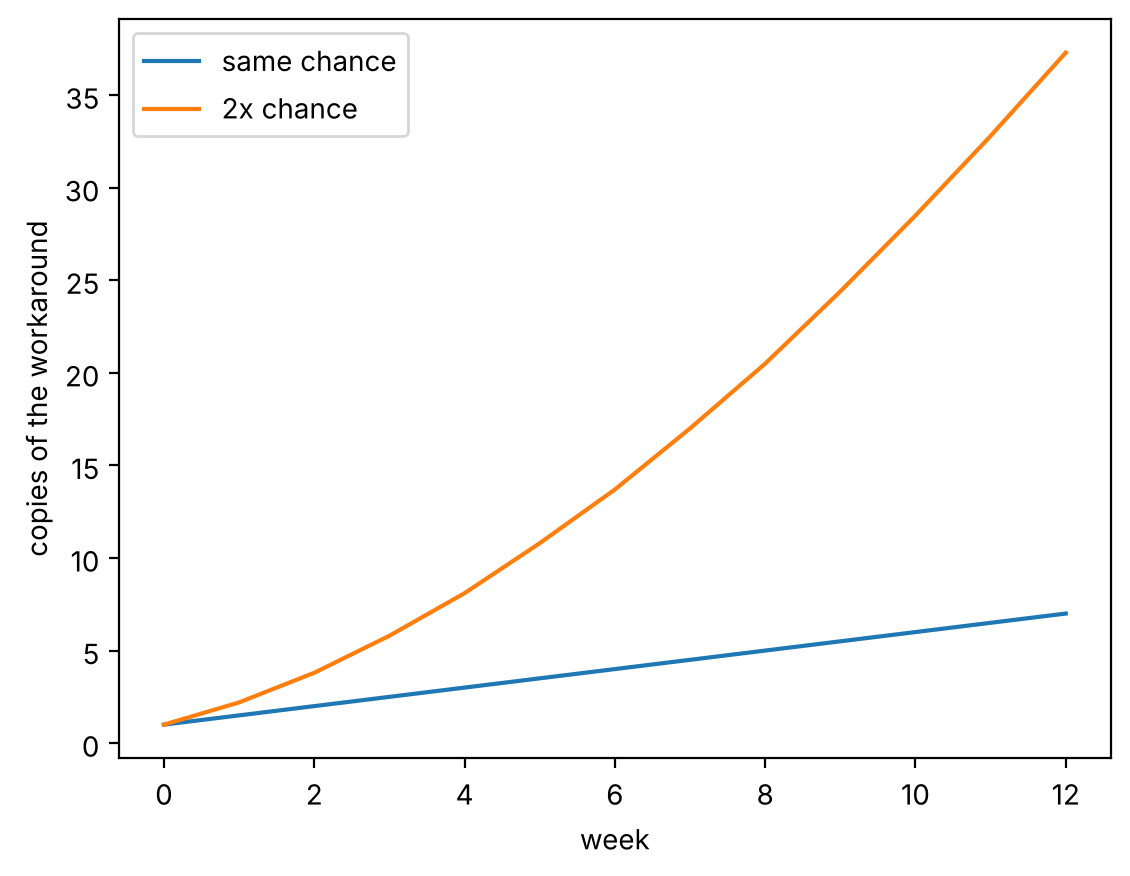

In [3]:
equal = mean_hist(bad_weight=1.0)
prefer2 = mean_hist(bad_weight=2.0)
print("一樣容易被挑中：", equal[0], "->", equal[-1])
print("被挑中機會 2 倍：", prefer2[0], "->", prefer2[-1])
plt.plot(equal, label="same chance")
plt.plot(prefer2, label="2x chance")
plt.xlabel("week"); plt.ylabel("copies of the workaround"); plt.legend(); plt.show()

## 3. 同樣的設定，各跑一次差多少？（改 seed 看看）

In [4]:
runs = [simulate(bad_weight=2.0, seed=s)[-1] for s in range(10)]
print(runs, "最少", min(runs), "最多", max(runs))

[36, 99, 3, 36, 12, 63, 61, 18, 17, 111] 最少 3 最多 111


## 4. 說明檔：AI 照做的比例 vs 一年後的數量（每週 200 段，跑 52 週）

In [5]:
for obey in (0.0, 0.3, 0.5, 0.7, 0.9):
    print(f"照做 {obey:.0%}：", mean_hist(runs=300, weeks=52, per_week=200, bad_weight=2.0, rule="prose", obey=obey)[-1])
print("自動檢查：", mean_hist(runs=300, weeks=52, per_week=200, bad_weight=2.0, rule="lint")[-1])

照做 0%： 4947.4


照做 30%： 885.6


照做 50%： 142.5


照做 70%： 21.4


照做 90%： 2.8


自動檢查： 1.0


## 5. 只清不擋會怎樣？

`invent`：AI 卡住時自己想出補洞寫法的機率（假設每段 0.5%）。

只清不擋，一年後： 34.8 ／清掉再加檢查： 0.0


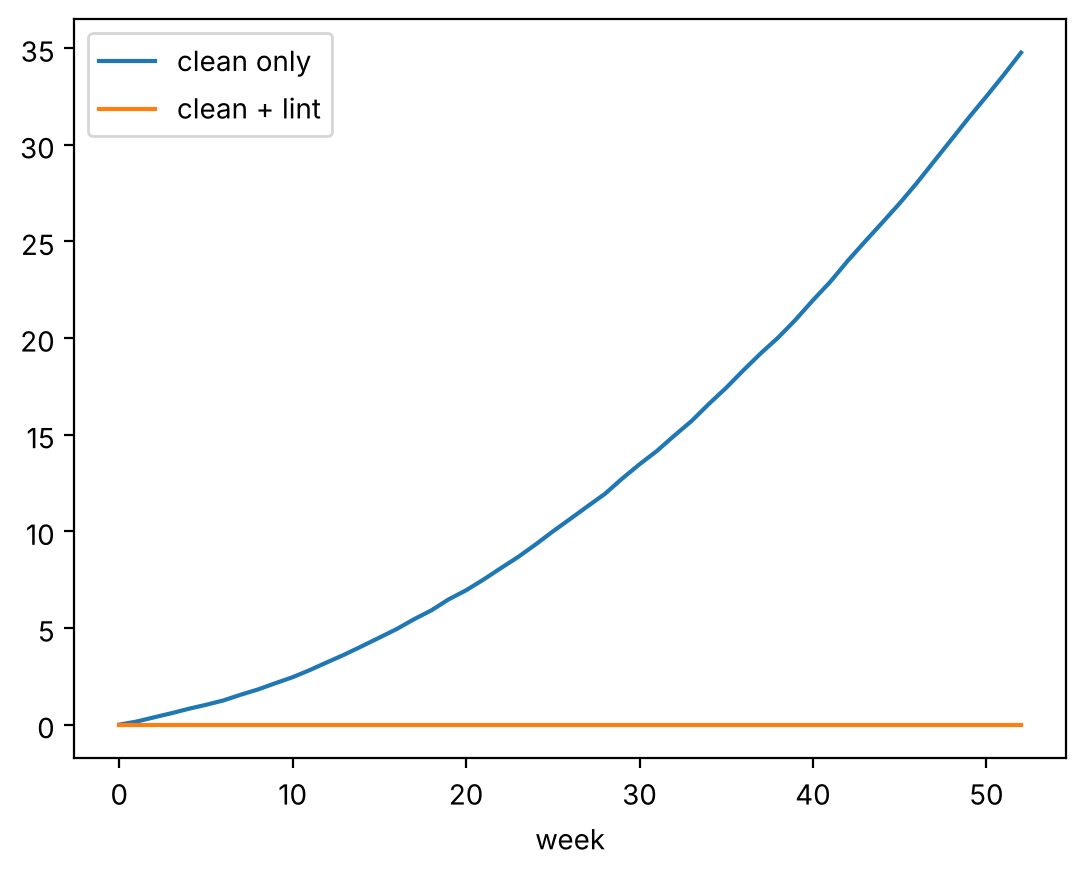

In [6]:
def after_cleanup(weeks=12, good=420, per_week=30, bad_weight=2.0, invent=0.005, lint=False, seed=0):
    """全部清掉之後再跑 weeks 週。invent：AI 卡住時自己想出補洞寫法的機率（假設每段 0.5%）。"""
    rng = random.Random(seed)
    bad, hist = 0, [0]
    for _ in range(weeks):
        for _ in range(per_week):
            p_bad = bad * bad_weight / (bad * bad_weight + good)
            if rng.random() < p_bad or rng.random() < invent:
                if lint:
                    good += 1
                else:
                    bad += 1
            else:
                good += 1
        hist.append(bad)
    return hist


clean_only = [sum(after_cleanup(weeks=52, seed=k)[i] for k in range(500)) / 500 for i in range(53)]
clean_lint = [sum(after_cleanup(weeks=52, seed=k, lint=True)[i] for k in range(500)) / 500 for i in range(53)]
print("只清不擋，一年後：", round(clean_only[-1], 1), "／清掉再加檢查：", round(clean_lint[-1], 1))
plt.plot(clean_only, label="clean only"); plt.plot(clean_lint, label="clean + lint")
plt.xlabel("week"); plt.legend(); plt.show()

## 6. 一個真的小檢查程式（lint）

規則：產品程式裡不准用 `setTimeout` 補洞，而且要告訴 AI 該怎麼改。試著在 `SAMPLE` 裡加一個檔案。

In [7]:
LINT_RULE = re.compile(r"\bsetTimeout\s*\(")
SAMPLE = {
    "src/chat/list.tsx": "const list = useChatList();\nrender(list);\n",
    "src/chat/input.tsx": "setTimeout(() => focusInput(), 0); // 先這樣補一下\n",
    "src/settings/panel.tsx": "const s = useSettings();\nsetTimeout(() => refresh(s), 50); // 跟上面一樣\n",
    "src/files/tree.tsx": "const tree = useFileTree();\nrender(tree);\n",
}


def lint(files):
    """真的會跑的小檢查：產品程式裡不准用 setTimeout 補洞，並告訴 agent 該怎麼改。"""
    out = []
    for name, code in files.items():
        for i, line in enumerate(code.splitlines(), 1):
            if LINT_RULE.search(line):
                out.append(f"{name}:{i}  不要用 setTimeout 補洞，改用元件的狀態更新，找出真正慢的原因")
    return out


print("\n".join(lint(SAMPLE)))

src/chat/input.tsx:1  不要用 setTimeout 補洞，改用元件的狀態更新，找出真正慢的原因
src/settings/panel.tsx:2  不要用 setTimeout 補洞，改用元件的狀態更新，找出真正慢的原因
